# Game AI Winner Prediction 

## Problem Statement
The objective of this project is to analyze PUBG gameplay data and build a machine learning model capable of predicting a player's final placement percentage (`winPlacePerc`) using gameplay-related features.

## Target Variable

`winPlacePerc`

This variable represents the player's final placement percentage and ranges
from 0 to 1. Therefore, this project is formulated as a regression problem.

## Project WorkFow
1. Problem Statement
2. Dataset Loading & Inspection
3. Data Types
4. Missing Value Analysis
5. Missing Value Treatment
6. Duplicate Analysis
7. Negative / Special Value Analysis
8. Zero Value Analysis
9. Target Variable Analysis
10. Categorical Variable Analysis
11. Feature Distribution
12. Feature Variability
13. Correlation Analysis
14. Correlation Heatmap
15. Scatterplot Analysis
16. Outlier Analysis
17. Identifier Removal
18. Leakage Discussion
19. Feature Engineering
20. Encoding
21. X/y Separation
22. Train-Test Split
23. Linear Regression
24. Random Forest
25. HistGradientBoosting
26. Model Comparison
27. Best Model Selection
28. Actual vs Predicted
29. Final Prediction Error
30. Findings
31. Conclusion

### Importing Liberaries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

import warnings 
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("PRCP-1012-GameWinnerPred.zip")

### Data Inspection 

In [3]:
df.head()
df.sample(10)

,Id,groupId,matchId,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,...,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc
53811,b9f0e27c9c4426,db48d73ae59bfc,6e65261028bc02,0,0,100.00,1,0,0,29,...,0,0.0,0,0.0,0,0,145.80,2,1500,0.0800
3174886,9eee80bbd522fa,23f9a06c0a3ffc,3c2bc0c4ba3ba3,0,0,64.20,0,0,0,84,...,0,0.0,0,0.0,0,0,49.70,2,0,0.0769
1795440,0a631702ec61be,cbf1e37239a968,5c1669f4611a6d,0,0,48.51,0,0,0,93,...,0,0.0,0,0.0,0,0,42.81,1,1504,0.0370
2257233,bc6219c74a093d,07d01d4d629c35,d59c400e1a107f,0,0,0.00,0,0,0,67,...,0,0.0,0,0.0,0,0,309.80,4,1460,0.3793
1706235,28f7fa7c8298b8,03202fca7b1dcf,3611330938e403,0,0,26.46,0,0,0,84,...,0,0.0,0,0.0,0,0,203.40,1,0,0.0769
104190,ec84978babb833,eb627c81fe3a86,7ccccb8a5cd256,0,1,69.42,0,0,1,84,...,0,0.0,0,0.0,0,0,744.90,2,0,0.1786
2892,0708696ca8ae27,b5bc4c3ee7b882,615ae16e0a4b3f,0,0,83.40,0,0,0,54,...,0,0.0,0,0.0,0,0,168.40,3,1624,0.7308
2669813,23e78ef4d7ea62,816bb652f722f8,b91078ed796e0c,0,0,0.00,0,0,0,72,...,0,0.0,0,0.0,0,0,79.07,1,0,0.2500
3718543,3934d0123b828d,22fa1f2efb123e,2147dae3d594ae,0,0,100.00,1,0,0,30,...,0,0.0,0,0.0,0,0,70.35,1,0,0.7872
3004880,fb9c4e19459d02,3b8782e6d56a38,8c80206937f90f,0,0,186.00,0,0,0,35,...,0,0.0,0,0.0,0,0,237.60,5,0,0.5000


In [4]:
print(df.dtypes)

Id                  object
groupId             object
matchId             object
assists              int64
boosts               int64
damageDealt        float64
DBNOs                int64
headshotKills        int64
heals                int64
killPlace            int64
killPoints           int64
kills                int64
killStreaks          int64
longestKill        float64
matchDuration        int64
matchType           object
maxPlace             int64
numGroups            int64
rankPoints           int64
revives              int64
rideDistance       float64
roadKills            int64
swimDistance       float64
teamKills            int64
vehicleDestroys      int64
walkDistance       float64
weaponsAcquired      int64
winPoints            int64
winPlacePerc       float64
dtype: object


In [5]:
missing = df.isnull().sum()

print(missing[missing > 0])
print("\nTotal missing values:", missing.sum())

winPlacePerc    1
dtype: int64

Total missing values: 1


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
print(df['winPlacePerc'].describe())
# df['winPlacePerc'].describe()

count    4.446965e+06
mean     4.728216e-01
std      3.074050e-01
min      0.000000e+00
25%      2.000000e-01
50%      4.583000e-01
75%      7.407000e-01
max      1.000000e+00
Name: winPlacePerc, dtype: float64


In [8]:
print(df['matchType'].value_counts())

matchType
squad-fpp           1756186
duo-fpp              996691
squad                626526
solo-fpp             536762
duo                  313591
solo                 181943
normal-squad-fpp      17174
crashfpp               6287
normal-duo-fpp         5489
flaretpp               2505
normal-solo-fpp        1682
flarefpp                718
normal-squad            516
crashtpp                371
normal-solo             326
normal-duo              199
Name: count, dtype: int64


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
assists,4446966.0,0.233815,0.588573,0.0,0.0,0.0000,0.000000,22.0
boosts,4446966.0,1.106908,1.715794,0.0,0.0,0.0000,2.000000,33.0
damageDealt,4446966.0,130.717138,170.780621,0.0,0.0,84.2400,186.000000,6616.0
DBNOs,4446966.0,0.657876,1.145743,0.0,0.0,0.0000,1.000000,53.0
headshotKills,4446966.0,0.226820,0.602155,0.0,0.0,0.0000,0.000000,64.0
heals,4446966.0,1.370147,2.679982,0.0,0.0,0.0000,2.000000,80.0
killPlace,4446966.0,47.599350,27.462937,1.0,24.0,47.0000,71.000000,101.0
killPoints,4446966.0,505.006042,627.504896,0.0,0.0,0.0000,1172.000000,2170.0
kills,4446966.0,0.924783,1.558445,0.0,0.0,0.0000,1.000000,72.0
killStreaks,4446966.0,0.543955,0.710972,0.0,0.0,0.0000,1.000000,20.0


In [10]:
df = df.dropna(subset=['winPlacePerc'])

print(df.shape)

(4446965, 29)


- The missing-value analysis identified only one missing observation, which occurred in the target variable winPlacePerc. Since the target value cannot be reliably imputed from the available information without introducing artificial information, the corresponding record was removed. This resulted in a dataset containing 4,446,965 observations.

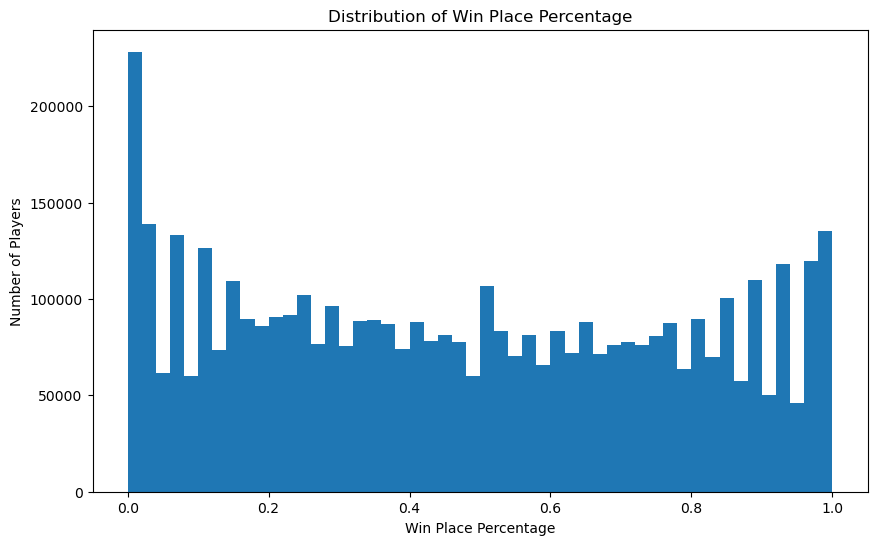

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(df['winPlacePerc'], bins=50)

plt.xlabel('Win Place Percentage')
plt.ylabel('Number of Players')
plt.title('Distribution of Win Place Percentage')
plt.show()

### Investigating the Rankpoints = -1

In [12]:
print("Number of rankPoints = -1:",
      (df['rankPoints'] == -1).sum())

print("\nPercentage:",
      (df['rankPoints'] == -1).mean() * 100)

Number of rankPoints = -1: 1701810

Percentage: 38.26902168107912


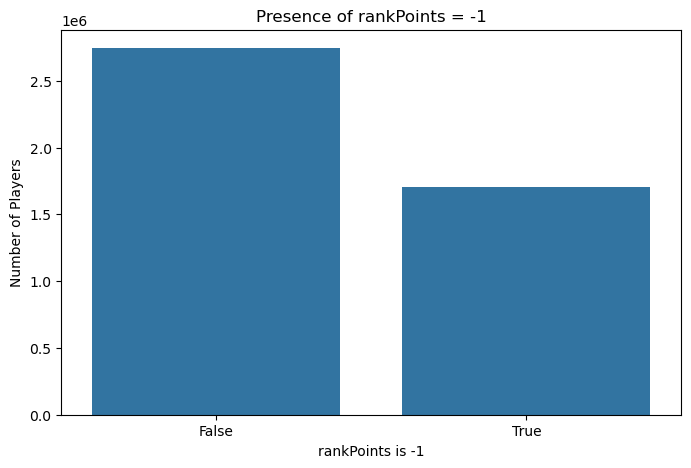

In [13]:
plt.figure(figsize=(8,5))

sns.countplot(
    x=(df['rankPoints'] == -1)
)

plt.title("Presence of rankPoints = -1")
plt.xlabel("rankPoints is -1")
plt.ylabel("Number of Players")

plt.show()

- The value -1 occurs frequently in rankPoints and therefore should not be treated as a random data-entry error. It likely represents unavailable or unranked information. Because this value has meaningful information about the ranking state, it is retained rather than blindly replacing it.

In [14]:
df['rankPoints'].value_counts().head(15)

rankPoints
-1       1701810
 1500     299741
 0         89509
 1480      48857
 1494      42612
 1490      42254
 1497      40174
 1496      38260
 1502      34873
 1505      32885
 1503      32173
 1510      28854
 1486      25508
 1493      24452
 1484      24126
Name: count, dtype: int64

In [15]:
df.groupby(df['rankPoints'] == -1)['winPlacePerc'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
rankPoints,,,,
False,2745155,0.473090,0.4583,0.307450
True,1701810,0.472388,0.4583,0.307332


### Zero-values Analysis

In [16]:
numeric_cols = df.select_dtypes(include=['number']).columns
zero_percentage = (
    (df[numeric_cols] == 0).mean() * 100
).sort_values(ascending=False)

display(
    zero_percentage.to_frame('Zero_Percentage')
)

,Zero_Percentage
roadKills,99.707756
vehicleDestroys,99.240965
teamKills,97.820311
swimDistance,93.495069
revives,86.797760
headshotKills,83.115451
assists,82.475554
rideDistance,74.419925
DBNOs,62.373641
killPoints,59.718167


- existing analysis found particularly high zero percentages for:

1. swimDistance ≈ 93.50%
2. revives ≈ 86.80%
3. headshotKills ≈ 83.12%
4. assists ≈ 82.48%
5. rideDistance ≈ 74.42%

- Zero values were investigated separately from missing values. In gameplay data, a zero often represents a legitimate event, such as no kills, no revives, no swimming, or no vehicle usage. Therefore, these zeros were retained.

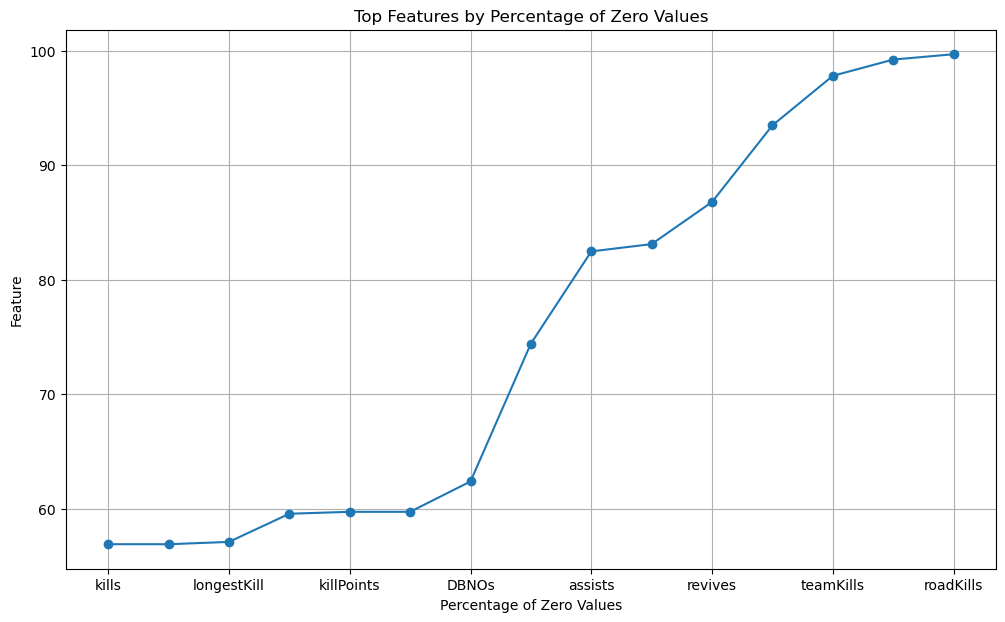

In [17]:
plt.figure(figsize=(12,7))

zero_percentage.head(15).sort_values().plot(kind='line', marker='o')

plt.title("Top Features by Percentage of Zero Values")
plt.xlabel("Percentage of Zero Values")
plt.ylabel("Feature")
plt.grid(True)
plt.show()

### The graph represents:
- This graph shows the proportion of records containing zero values in selected gameplay features.
  ### The Output shows -
  A high percentage of zeros indicates that the corresponding activity did not occur for many players.

### Target-Variable Analysis

In [18]:
print(df['winPlacePerc'].describe())

count    4.446965e+06
mean     4.728216e-01
std      3.074050e-01
min      0.000000e+00
25%      2.000000e-01
50%      4.583000e-01
75%      7.407000e-01
max      1.000000e+00
Name: winPlacePerc, dtype: float64


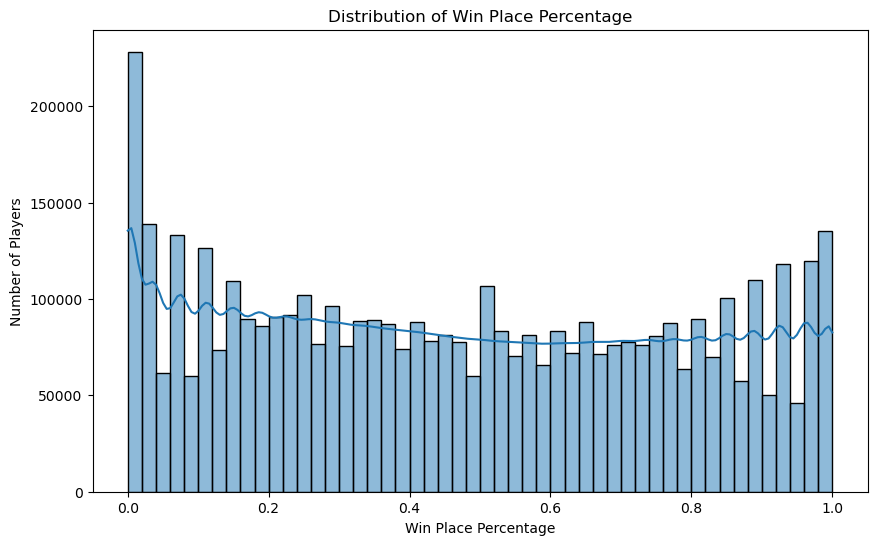

In [19]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['winPlacePerc'],
    bins=50,
    kde=True
)

plt.title("Distribution of Win Place Percentage")
plt.xlabel("Win Place Percentage")
plt.ylabel("Number of Players")

plt.show()

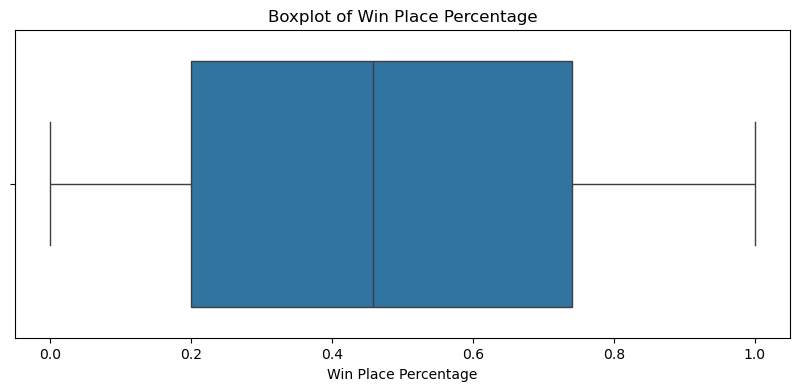

In [20]:
plt.figure(figsize=(10,4))

sns.boxplot(x=df['winPlacePerc'])

plt.title("Boxplot of Win Place Percentage")
plt.xlabel("Win Place Percentage")

plt.show()

- The data shows:

1. Mean   ≈ 0.473
2. Median ≈ 0.458
3. Minimum = 0
4. Maximum = 1

- The target variable ranges from 0 to 1, with a mean of approximately 0.473 and a median of approximately 0.458. The relatively close mean and median indicate that the overall distribution is not extremely skewed. The broad range shows that the dataset contains players across different levels of final placement, making it suitable for a regression-based prediction task.

### Match Type Analysis

In [21]:
match_counts = df['matchType'].value_counts()

display(match_counts)

matchType
squad-fpp           1756186
duo-fpp              996691
squad                626526
solo-fpp             536761
duo                  313591
solo                 181943
normal-squad-fpp      17174
crashfpp               6287
normal-duo-fpp         5489
flaretpp               2505
normal-solo-fpp        1682
flarefpp                718
normal-squad            516
crashtpp                371
normal-solo             326
normal-duo              199
Name: count, dtype: int64

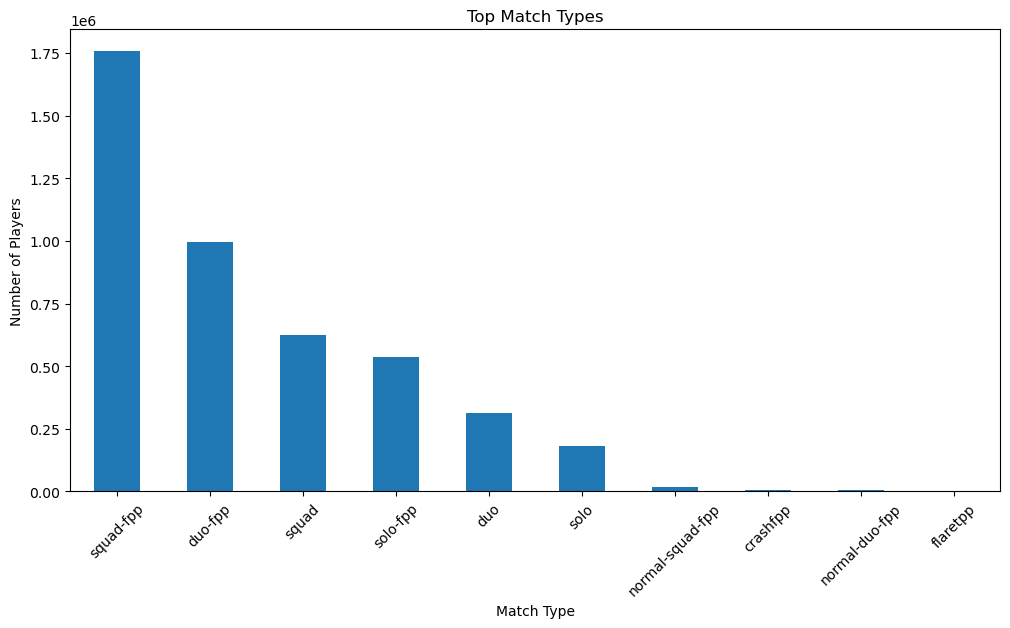

In [22]:
plt.figure(figsize=(12,6))

match_counts.head(10).plot(kind='bar')

plt.title("Top Match Types")
plt.xlabel("Match Type")
plt.ylabel("Number of Players")

plt.xticks(rotation=45)

plt.show()

- The bars show how frequently each match type occurs in the dataset.
- The dataset contains multiple PUBG match formats, with some match types occurring substantially more frequently than others.The distribution of match types is uneven, with a small number of match formats accounting for most observations. Since match type can influence player behaviour and match dynamics, it is retained as a categorical predictor and encoded before machine-learning modelling
-  Squad and FPP-based match types account for a substantial portion of the observations. Match type may influence player behaviour and should therefore be considered during modelling.

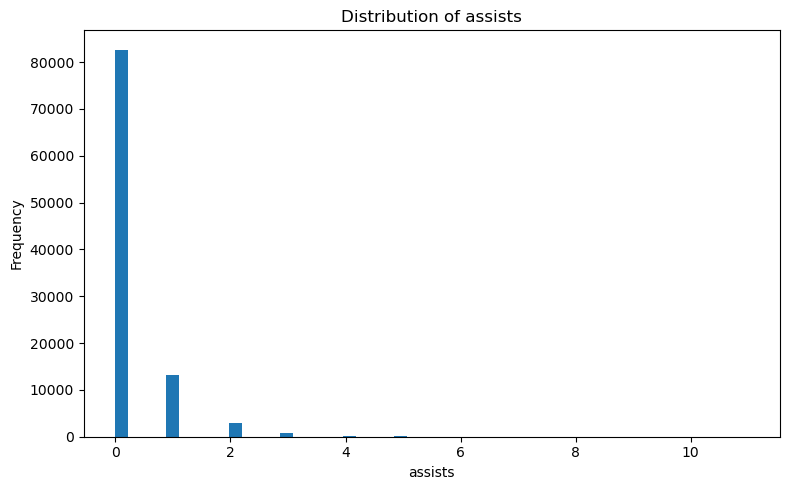

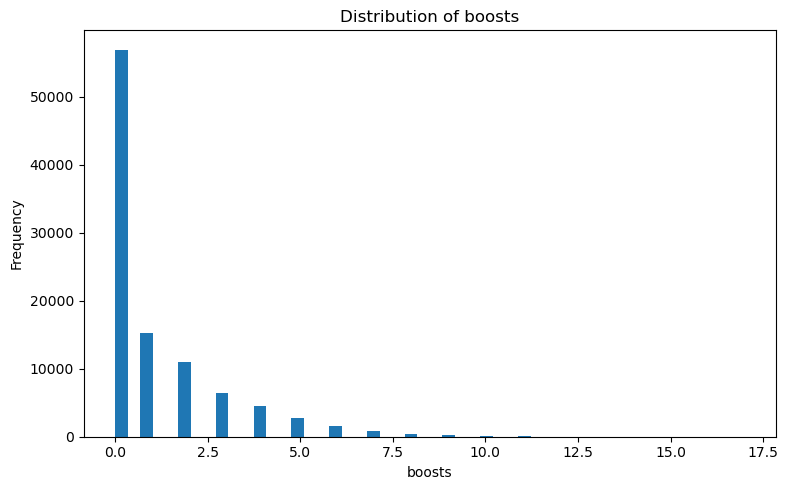

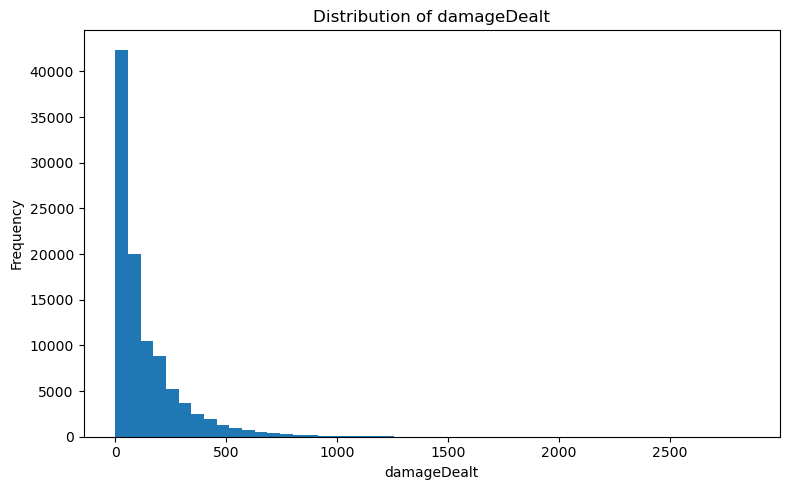

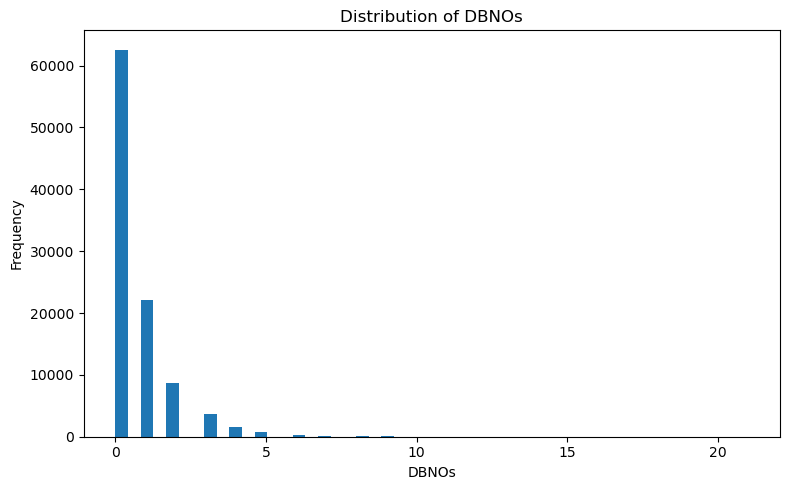

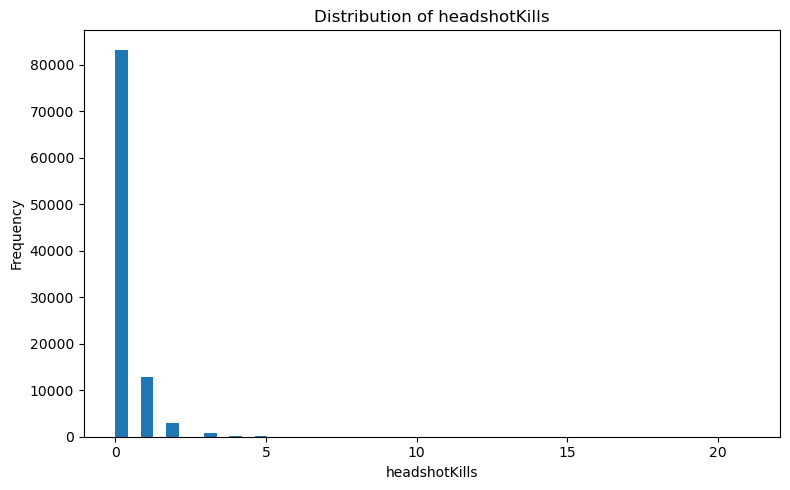

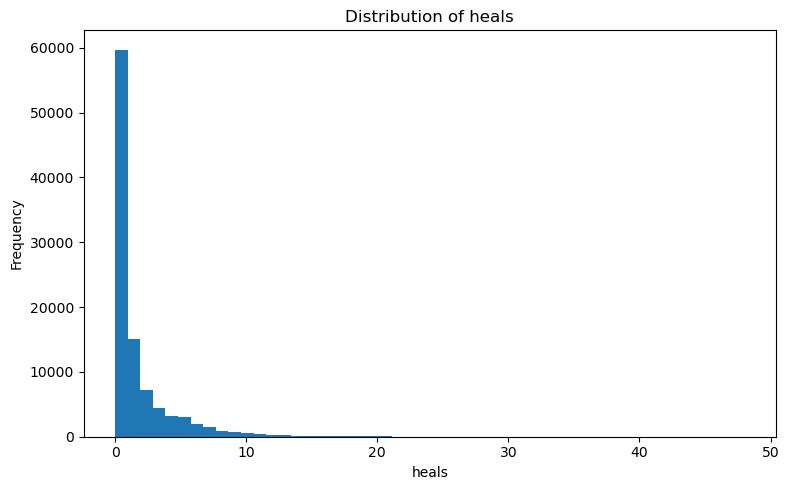

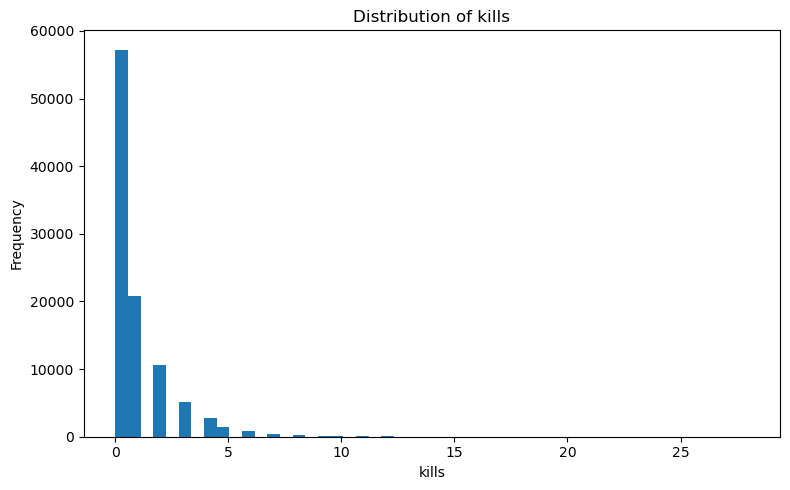

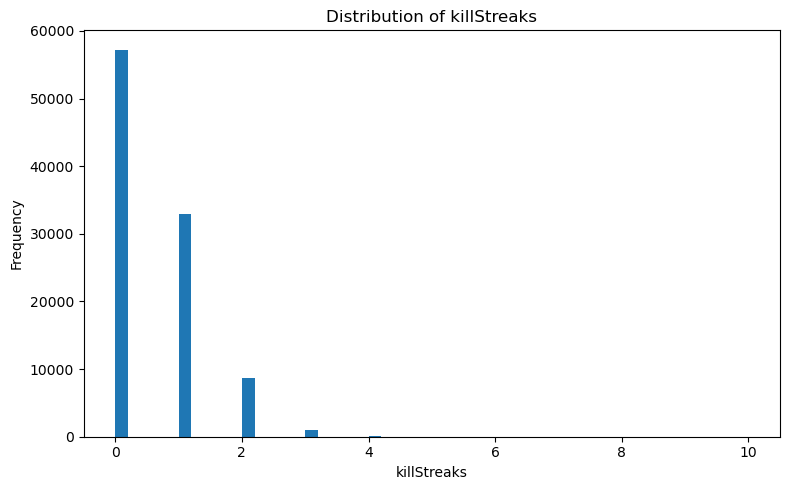

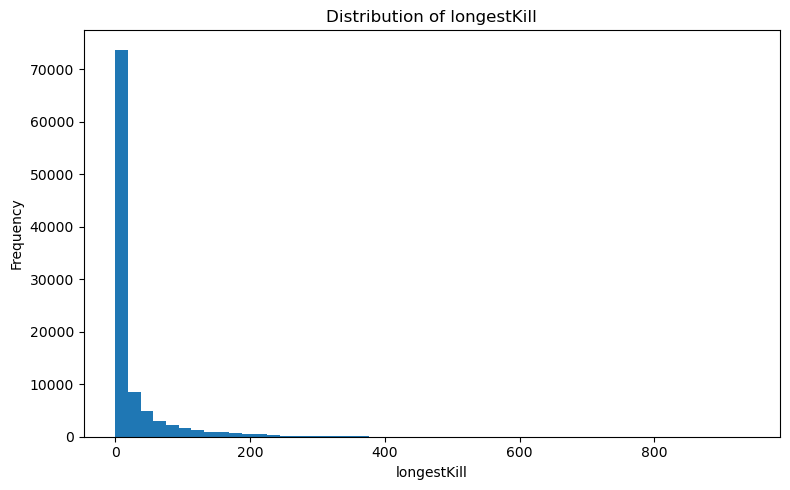

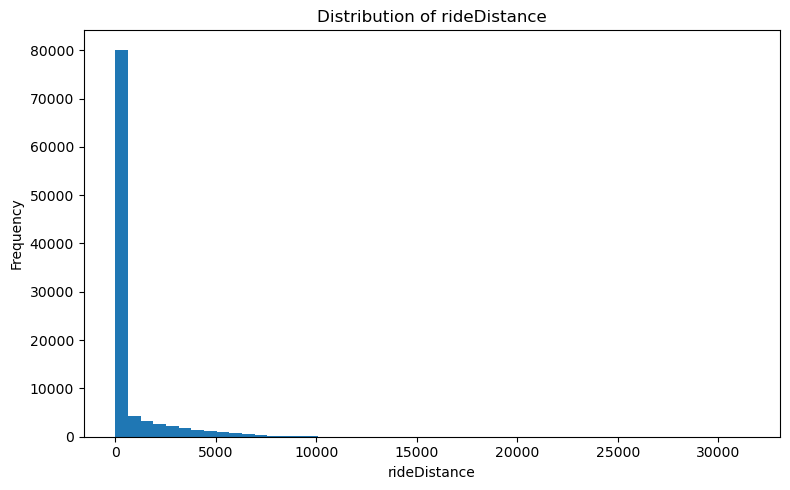

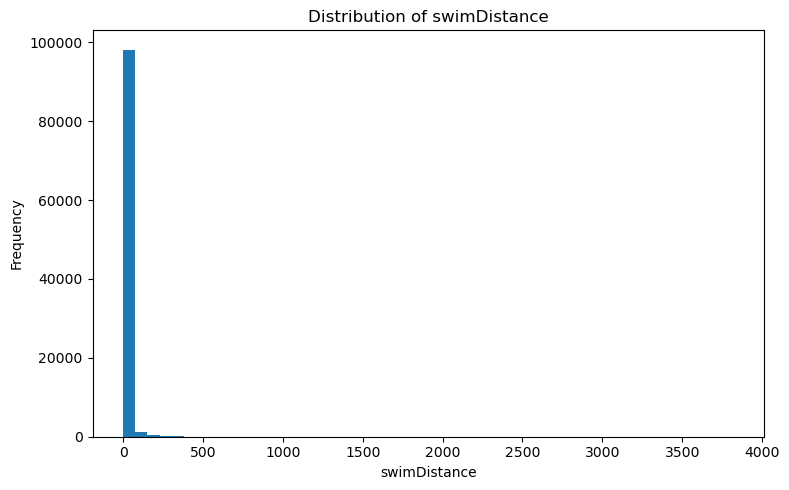

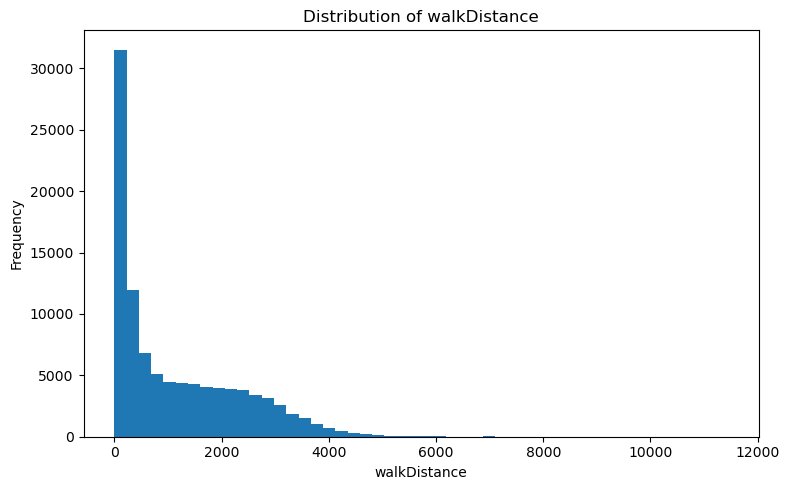

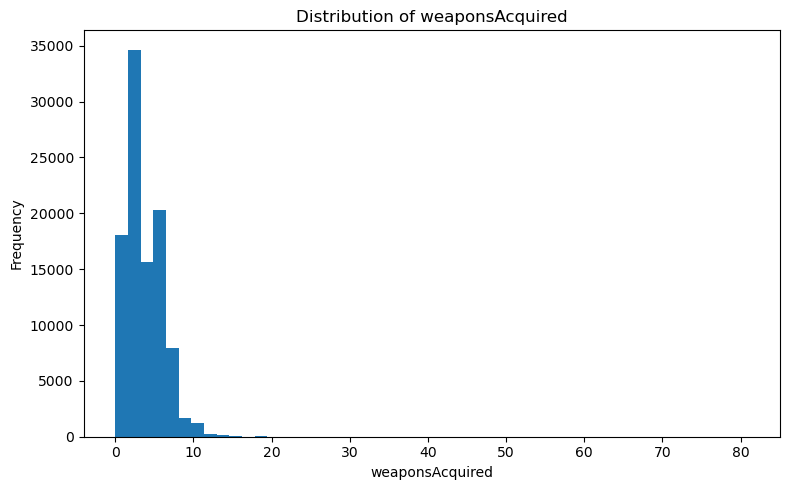

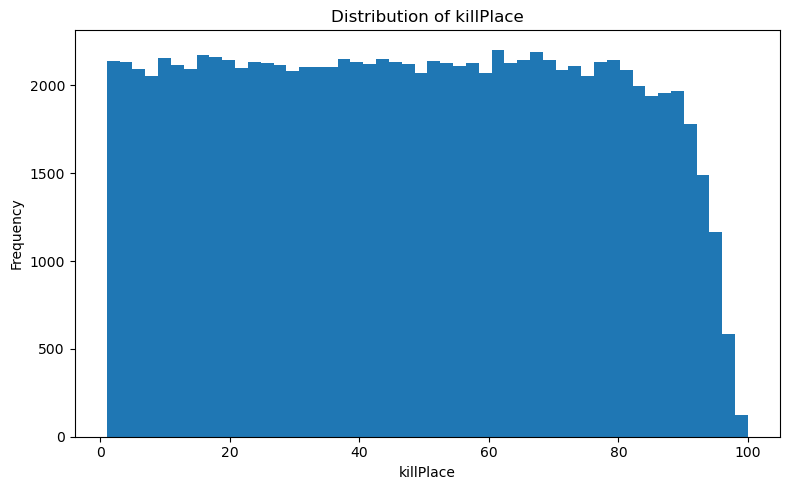

In [23]:
# Taking a random sample for visualization
sample_df = df.sample(n=100000, random_state=42)

features = [
    'assists',
    'boosts',
    'damageDealt',
    'DBNOs',
    'headshotKills',
    'heals',
    'kills',
    'killStreaks',
    'longestKill',
    'rideDistance',
    'swimDistance',
    'walkDistance',
    'weaponsAcquired',
    'killPlace']
    
for feature in features:
    plt.figure(figsize=(8, 5))
    plt.hist(sample_df[feature], bins=50)
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {feature}')
    plt.tight_layout()
    plt.show()

### Feature Variability

In [24]:
features = [
    'assists',
    'boosts',
    'damageDealt',
    'DBNOs',
    'headshotKills',
    'heals',
    'kills',
    'killStreaks',
    'longestKill',
    'revives',
    'rideDistance',
    'swimDistance',
    'walkDistance',
    'weaponsAcquired'
]

variability = df[features].agg(
    ['mean', 'std', 'min', 'median', 'max']
).T

variability['CV'] = (
    variability['std'] / variability['mean']
).replace([np.inf, -np.inf], np.nan)

variability = variability.sort_values(
    'CV',
    ascending=False
)

display(variability)

,mean,std,min,median,max,CV
swimDistance,4.509323,30.502203,0.0,0.00,3823.0,6.764253
revives,0.164659,0.472167,0.0,0.00,39.0,2.867545
headshotKills,0.226820,0.602155,0.0,0.00,64.0,2.654776
assists,0.233815,0.588573,0.0,0.00,22.0,2.517260
rideDistance,606.115805,1498.343654,0.0,0.00,40710.0,2.472042
longestKill,22.997600,50.972623,0.0,0.00,1094.0,2.216432
heals,1.370148,2.679982,0.0,0.00,80.0,1.955981
DBNOs,0.657876,1.145743,0.0,0.00,53.0,1.741580
kills,0.924784,1.558445,0.0,0.00,72.0,1.685200
boosts,1.106908,1.715794,0.0,0.00,33.0,1.550078


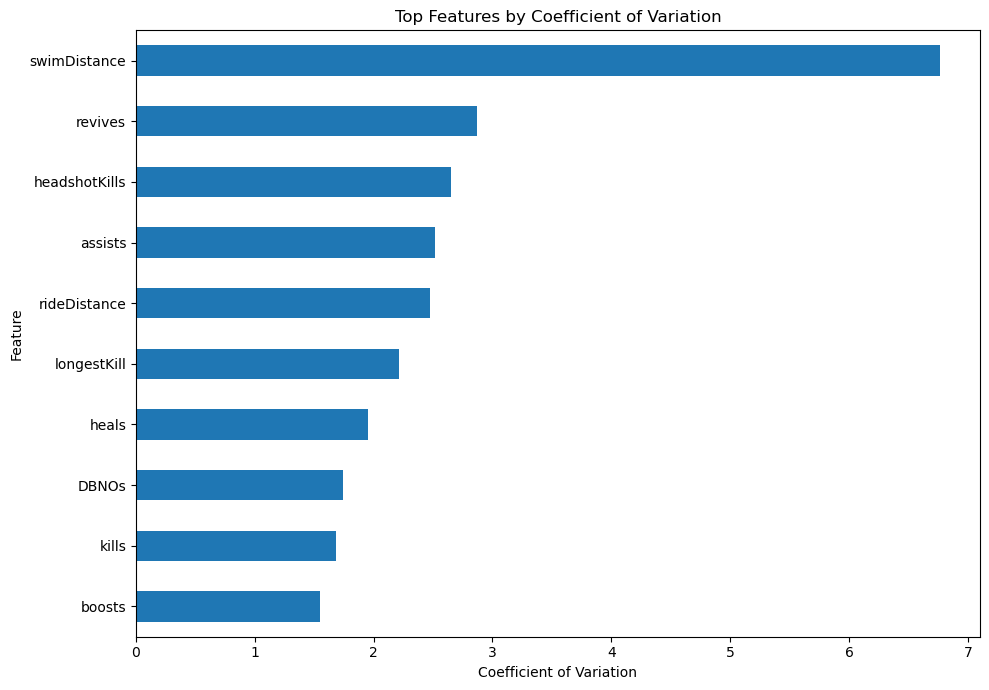

In [25]:
plt.figure(figsize=(10,7))

variability['CV'].head(10).sort_values().plot(
    kind='barh'
)

plt.title("Top Features by Coefficient of Variation")
plt.xlabel("Coefficient of Variation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

- This graph compares the variability of numerical features using measures such as standard deviation.
- Features with larger values exhibit greater numerical spread, while smaller values indicate more concentrated observations.

- Coefficient of Variation was used to compare relative variability among features with different scales. swimDistance, headshotKills, assists, and rideDistance show particularly high relative variability, indicating that player behaviour differs considerably for these activities.

- The features demonstrate substantially different levels of variability. Distance-related and activity-related variables generally exhibit greater dispersion than several combat variables. The substantial differences in relative variability indicate that player behaviour varies considerably across gameplay activities. This analysis also highlights why feature scaling is appropriate for scale-sensitive models such as Linear Regression, such as Linear Regression with standardization.

### Correlation with Target 

In [26]:
correlation = df[numeric_cols].corr()['winPlacePerc'].sort_values(
    ascending=False)

print(correlation)

winPlacePerc       1.000000
walkDistance       0.810888
boosts             0.634234
weaponsAcquired    0.583806
damageDealt        0.440507
heals              0.427857
kills              0.419916
longestKill        0.410154
killStreaks        0.377566
rideDistance       0.342915
assists            0.299441
DBNOs              0.279970
headshotKills      0.277722
revives            0.240881
swimDistance       0.149607
vehicleDestroys    0.073436
numGroups          0.039621
maxPlace           0.037377
roadKills          0.034544
teamKills          0.015943
rankPoints         0.013523
killPoints         0.012908
winPoints          0.007061
matchDuration     -0.005171
killPlace         -0.719069
Name: winPlacePerc, dtype: float64


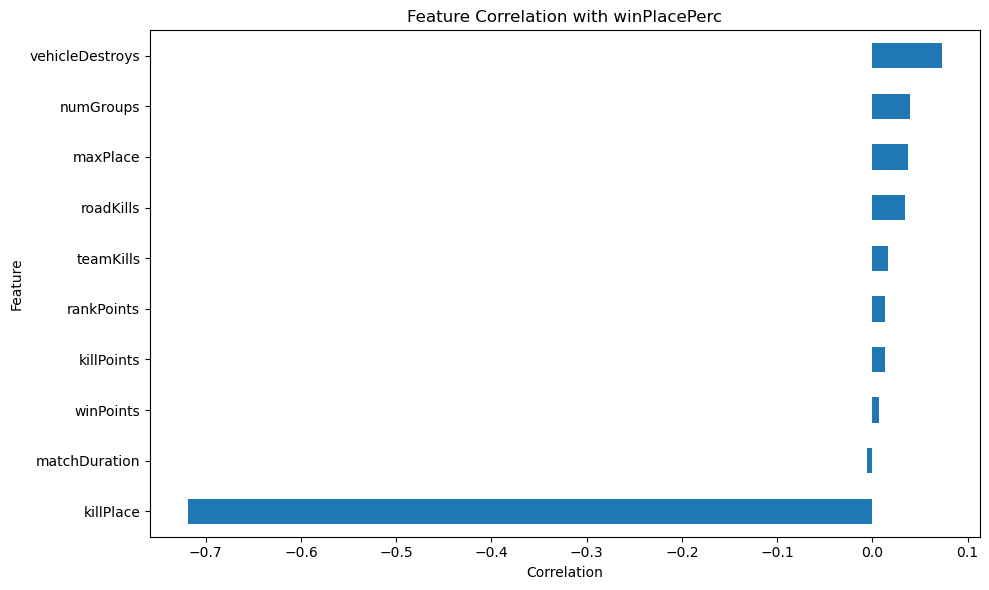

In [68]:
target_corr = correlation.drop('winPlacePerc')
plt.figure(figsize=(10,6))

target_corr.tail(10).sort_values().plot(
    kind='barh')

plt.title("Feature Correlation with winPlacePerc")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.tight_layout()

plt.show()

| Feature           | Correlation |
| ----------------- | ----------: |
| `walkDistance`    |       0.811 |
| `boosts`          |       0.634 |
| `weaponsAcquired` |       0.584 |
| `damageDealt`     |       0.441 |
| `heals`           |       0.428 |
| `kills`           |       0.420 |
| `longestKill`     |       0.410 |
| `killStreaks`     |       0.378 |
| `rideDistance`    |       0.343 |
| `assists`         |       0.299 |
| `killPlace`       |      -0.719 |

- walkDistance has the strongest positive correlation with winPlacePerc, while killPlace has a strong negative correlation. Other gameplay indicators such as boosts, weapons acquired, damage dealt, kills, healing and longest kill also show positive relationships with placement percentage.


## Correlation Heatmap
- The correlation heatmap measures the linear relationship between numerical variables.

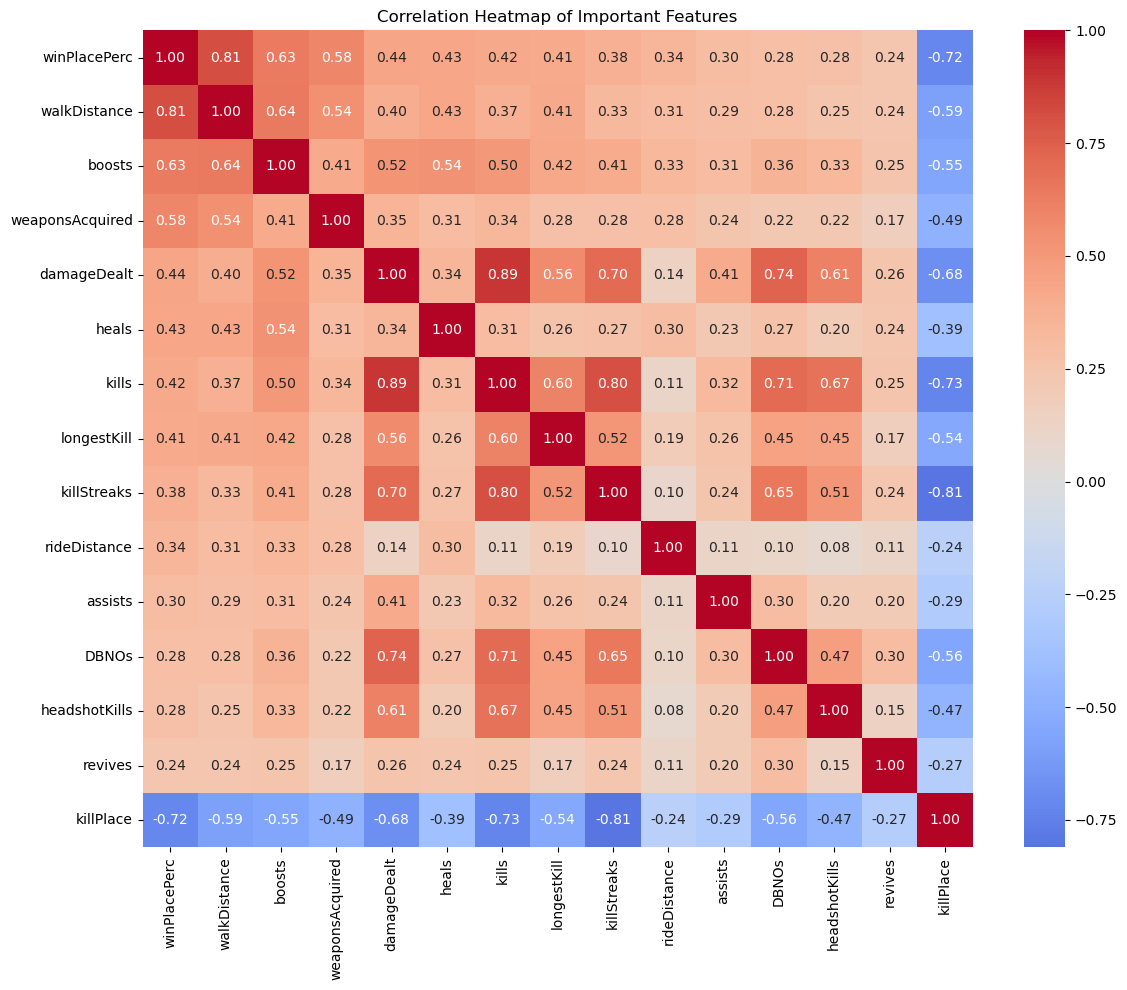

In [28]:
top_corr_features = [
    'winPlacePerc',
    'walkDistance',
    'boosts',
    'weaponsAcquired',
    'damageDealt',
    'heals',
    'kills',
    'longestKill',
    'killStreaks',
    'rideDistance',
    'assists',
    'DBNOs',
    'headshotKills',
    'revives',
    'killPlace']

corr_matrix = df[top_corr_features].corr()

plt.figure(figsize=(12,10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap of Important Features")
plt.tight_layout()
plt.show()

- The correlation heatmap provides an overview of linear relationships between gameplay features and the target. It also helps identify potentially redundant variables and guides subsequent feature selection.

### -- Correlation ranges from:
- -1 → Strong negative relationship
- 0 → No linear relationship
- +1 → Strong positive relationship

- analysis showed particularly strong relationships with winPlacePerc, including:
-  walkDistance    ≈ +0.81
- boosts          ≈ +0.63
- weaponsAcquired ≈ +0.58
- damageDealt     ≈ +0.44
- heals           ≈ +0.43
- kills           ≈ +0.42

- Observation:

The correlation analysis indicates that movement and gameplay activity are strongly associated with final placement. walkDistance demonstrates the strongest positive correlation with winPlacePerc among the listed variables, suggesting that players who survive longer and cover greater distances tend to achieve better placements. Other variables such as boosts, weapons acquired, damage dealt, healing activity and kills also show positive associations with final placement.

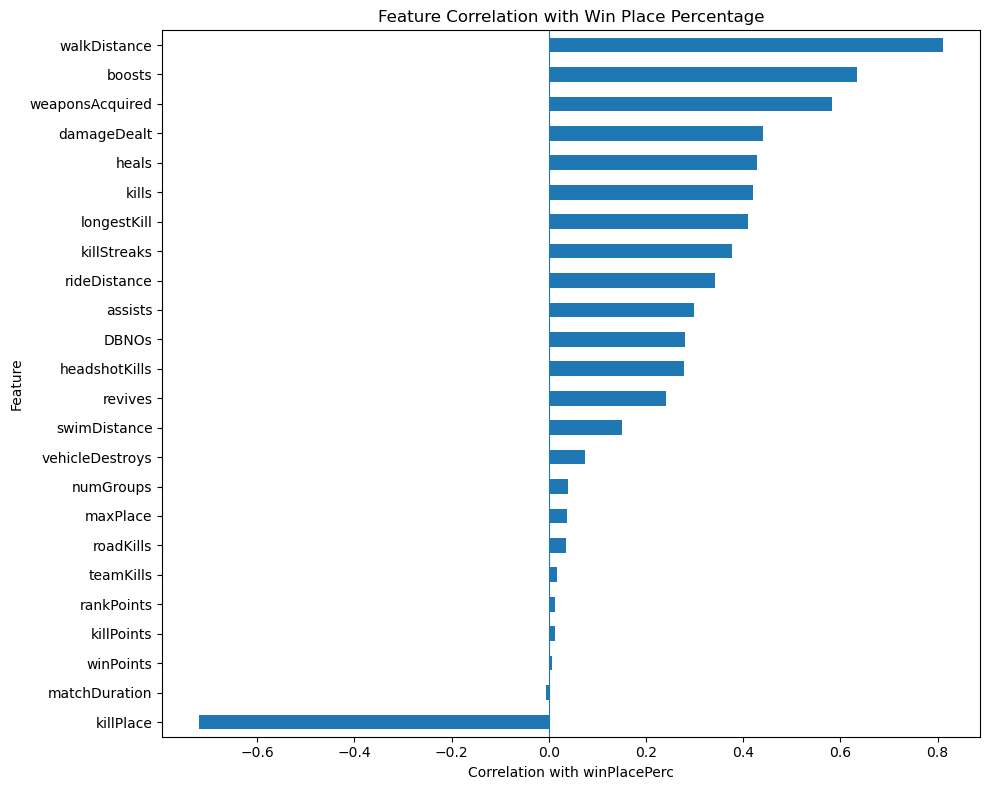

In [69]:
corr_target = (
    df[numeric_cols]
    .corr()['winPlacePerc']
    .drop('winPlacePerc')
    .sort_values())

plt.figure(figsize=(10, 8))

corr_target.plot(kind='barh')

plt.xlabel('Correlation with winPlacePerc')
plt.ylabel('Feature')
plt.title('Feature Correlation with Win Place Percentage')

plt.axvline(0, linewidth=0.8)

plt.tight_layout()
plt.show()

- Observations
The analysis identifies potential extreme observations in several gameplay variables. These observations represent unusually high or low gameplay activity. Because extreme values can correspond to genuine player behaviour, they were inspected rather than automatically deleted. Removing valid extreme observations could reduce the ability of the model to represent high-performing players.

### Scatterplots of Important Features vs Target

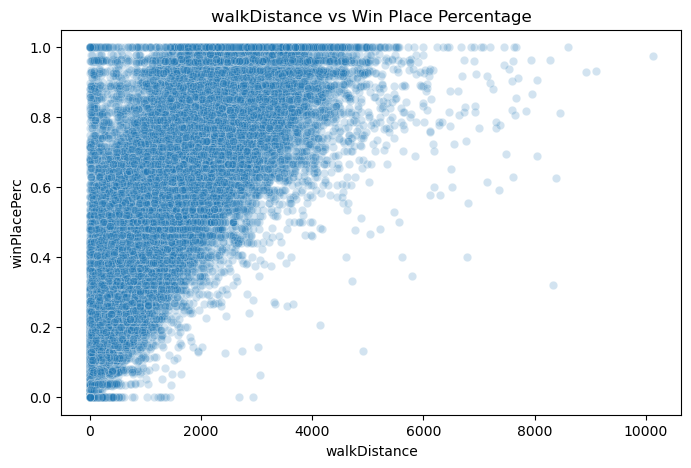

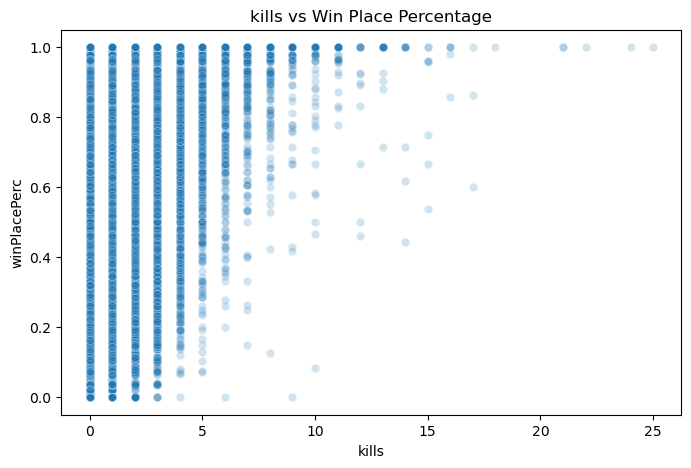

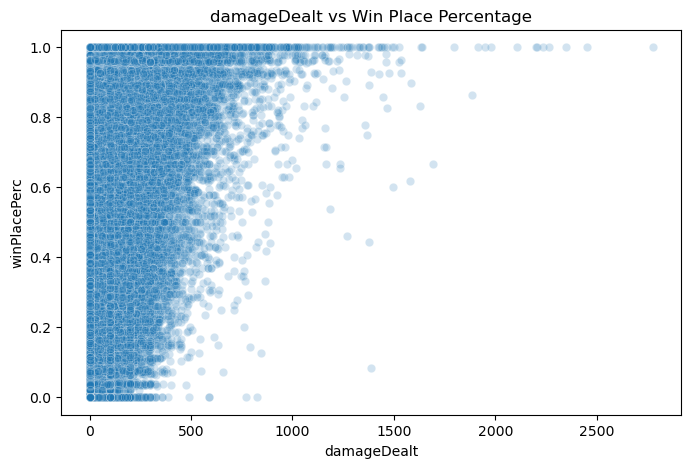

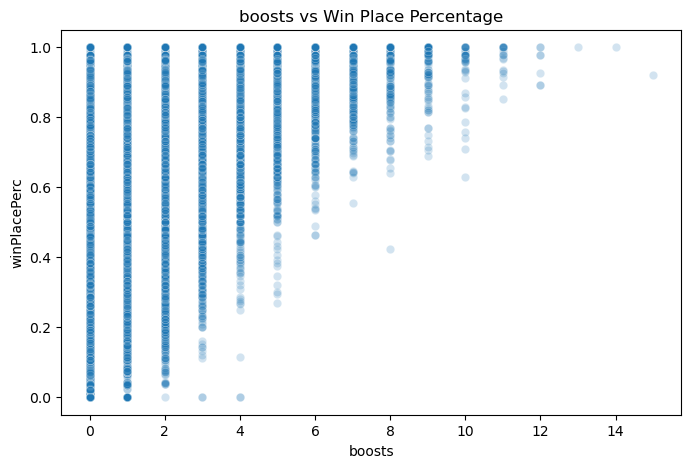

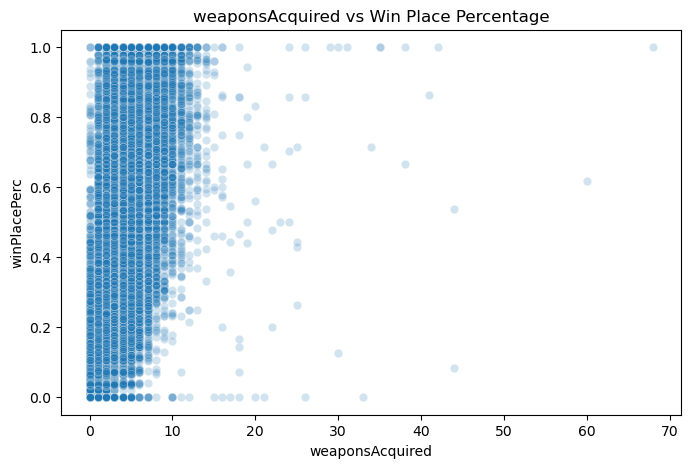

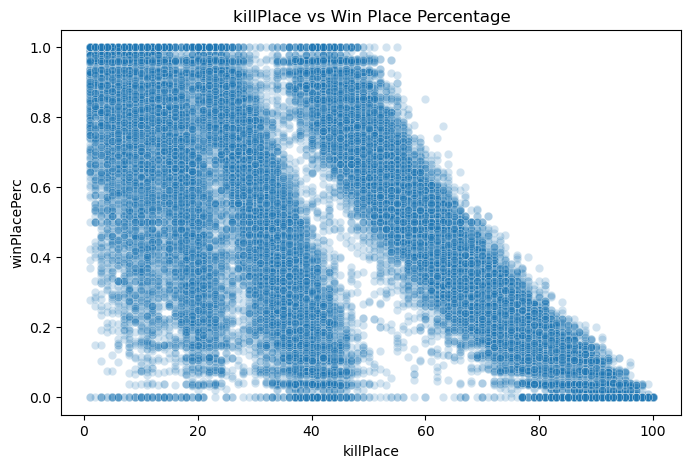

In [29]:
scatter_features = [
    'walkDistance',
    'kills',
    'damageDealt',
    'boosts',
    'weaponsAcquired',
    'killPlace'
]

for col in scatter_features:

    sample = df[[col, 'winPlacePerc']].sample(
        50000,
        random_state=42
    )

    plt.figure(figsize=(8,5))

    sns.scatterplot(
        data=sample,
        x=col,
        y='winPlacePerc',
        alpha=0.2
    )

    plt.title(f"{col} vs Win Place Percentage")
    plt.xlabel(col)
    plt.ylabel("winPlacePerc")

    plt.show()

- Observations in accordance to the graphs displayed
1. walkDistance vs winPlacePerc:

The scatter plot demonstrates a clear positive association between walking distance and final placement. Higher placement percentages are generally associated with greater movement distance. However, considerable variation remains at individual distance levels, indicating that movement alone cannot fully explain final placement.

2. kills vs winPlacePerc:

The relationship between kills and final placement is positive but less pronounced than the relationship observed for movement distance. This suggests that eliminating opponents contributes to successful placement, but survival and movement behaviour are also important components of overall performance.

3. damageDealt vs winPlacePerc:

Damage dealt demonstrates a positive relationship with final placement. However, the dispersion of observations indicates that high damage alone does not guarantee a high final placement. This reinforces the importance of considering multiple gameplay characteristics simultaneously.

4. weaponsAcquired vs winPlacePerc:

The graph indicates a positive association between the number of weapons acquired and final placement. Players who progress further through a match generally have greater opportunities to acquire equipment. However, the relationship is not perfectly linear, suggesting that equipment acquisition is only one component of successful gameplay.

### Outlier Analysis
The graph displays the number of observations identified as potential outliers for each numerical feature.

In [32]:
outlier_features = [
    'assists',
    'boosts',
    'damageDealt',
    'DBNOs',
    'headshotKills',
    'heals',
    'kills',
    'killStreaks',
    'longestKill',
    'maxPlace',
    'numGroups',
    'revives',
    'rideDistance',
    'roadKills',
    'swimDistance',
    'teamKills',
    'vehicleDestroys',
    'walkDistance',
    'weaponsAcquired' ]

outlier_results = []

for col in outlier_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    percentage = count / len(df) * 100

    outlier_results.append([
        col,
        Q1,
        Q3,
        IQR,
        lower,
        upper,
        count,
        percentage
    ])

outlier_df = pd.DataFrame(
    outlier_results,
    columns=[
        'Feature',
        'Q1',
        'Q3',
        'IQR',
        'Lower_Bound',
        'Upper_Bound',
        'Outlier_Count',
        'Outlier_Percentage']
)

outlier_df = outlier_df.sort_values(
    'Outlier_Percentage',
    ascending=False )

display(outlier_df)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
12,rideDistance,0.0,0.191,0.191,-0.2865,0.4775,1110282,24.967185
0,assists,0.0,0.000,0.000,0.0000,0.0000,779306,17.524446
4,headshotKills,0.0,0.000,0.000,0.0000,0.0000,750850,16.884549
9,maxPlace,28.0,49.000,21.000,-3.5000,80.5000,701861,15.782922
10,numGroups,27.0,47.000,20.000,-3.0000,77.0000,698800,15.714088
8,longestKill,0.0,21.320,21.320,-31.9800,53.3000,614427,13.816772
11,revives,0.0,0.000,0.000,0.0000,0.0000,587099,13.202240
6,kills,0.0,1.000,1.000,-1.5000,2.5000,516699,11.619138
5,heals,0.0,2.000,2.000,-3.0000,5.0000,326055,7.332079
3,DBNOs,0.0,1.000,1.000,-1.5000,2.5000,294831,6.629937


- IQR analysis identified several statistical outliers. However, because these observations can represent legitimate high-performance or unusual gameplay behaviour, they were not automatically removed. Removing them could eliminate valuable information about exceptional gameplay.

### Removing Identifier Columns 
Identifier variables were excluded from model training because they identify individual observations, groups or matches rather than representing gameplay behaviour.

In [33]:
id_columns = [
    'Id',
    'groupId',
    'matchId'
]

df_model = df.drop(
    columns=id_columns
)

print(df_model.shape)

(4446965, 26)


### Potential Data Leakage
- strongest negative correlation is:

killPlace ≈ -0.719

- The model is intended to predict final placement based on completed gameplay statistics. Therefore, gameplay-derived ranking variables are retained. If the model were intended for real-time early-game prediction, these variables would require separate leakage analysis.

# Feature Engineering

## Total Movement

In [34]:
df_model['totalDistance'] = (
    df_model['walkDistance'] +
    df_model['rideDistance'] +
    df_model['swimDistance']
)

### Total combat activity

In [35]:
df_model['combatScore'] = (
    df_model['kills'] +
    df_model['assists'] +
    df_model['DBNOs']
)

### Healing and boost activity

In [36]:
df_model['supportItems'] = (
    df_model['heals'] +
    df_model['boosts']
)

### Total elimination activity

In [37]:
df_model['totalKills'] = (
    df_model['kills'] +
    df_model['roadKills'] +
    df_model['teamKills']
)

### Damage per kill

In [70]:
df_model['damagePerKill'] = (
    df_model['damageDealt'] /
    (df_model['kills'] )
)

### Weapons per distance

In [39]:
df_model['weaponsPerDistance'] = (
    df_model['weaponsAcquired'] /
    (df_model['totalDistance'] + 1)
)

In [40]:
df_model = pd.get_dummies(
    df_model,
    columns=['matchType'],
    drop_first=True,
    dtype=int
)

### Separate X and y

In [41]:
X = df_model.drop(
    columns=['winPlacePerc']
)

y = df_model['winPlacePerc']

In [42]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("Categorical columns in X:")
print(X.select_dtypes(include='object').columns.tolist())

X shape: (4446965, 45)
y shape: (4446965,)
Categorical columns in X:
[]


### Train-Test Split

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [44]:
print(df_model.dtypes)

assists                         int64
boosts                          int64
damageDealt                   float64
DBNOs                           int64
headshotKills                   int64
heals                           int64
killPlace                       int64
killPoints                      int64
kills                           int64
killStreaks                     int64
longestKill                   float64
matchDuration                   int64
maxPlace                        int64
numGroups                       int64
rankPoints                      int64
revives                         int64
rideDistance                  float64
roadKills                       int64
swimDistance                  float64
teamKills                       int64
vehicleDestroys                 int64
walkDistance                  float64
weaponsAcquired                 int64
winPoints                       int64
winPlacePerc                  float64
totalDistance                 float64
combatScore 

### Scaling

In [45]:
scaler = StandardScaler()

### Model1- Linear Regression
Used as a baseline model. It is simple, fast, easy to interpret, and helps determine how well a basic linear relationship can predict player placement.

In [47]:
linear_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_pred)
)

linear_r2 = r2_score(
    y_test,
    linear_pred
)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)


Linear Regression Results
-------------------------
MAE : 0.08964819040095434
RMSE: 0.12251291151235931
R²  : 0.8409463414165814


### Model 2- Random Forest
Chosen because PUBG gameplay has nonlinear relationships and interactions between features such as kills, movement, damage, healing, and boosts. Random Forest can capture these complex patterns and is less sensitive to outliers and feature scaling.

Because the dataset contains over 4.4 million observations, a reproducible sample of 300,000 training observations was used for the computationally intensive tree-based models. The same test set was retained for evaluating all models

In [50]:
sample_size = min(300000, len(X_train))

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X_train),
    size=sample_size,
    replace=False
)

X_train_sample = X_train.iloc[sample_indices]
y_train_sample = y_train.iloc[sample_indices]

print("Random Forest training data:")
print(X_train_sample.shape)

Random Forest training data:
(300000, 45)


In [51]:
rf_model = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='median')
    ),
    (
        'model',
        RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_split=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(
    X_train_sample,
    y_train_sample
)

rf_pred = rf_model.predict(X_test)

In [52]:
rf_mae = mean_absolute_error(y_test, rf_pred )

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred )
)

rf_r2 = r2_score( y_test, rf_pred )

print("Random Forest")
print("-------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest
-------------------------
MAE : 0.06023182400276025
RMSE: 0.0851090573730281
R²  : 0.9232406121957231


### Model 3- Histgradient Boosting
Chosen because the dataset is very large and contains complex nonlinear relationships. Its histogram-based approach is computationally efficient for large datasets and can provide strong predictive performance.

In [54]:
from sklearn.ensemble import HistGradientBoostingRegressor

hist_model = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='median')
    ),
    (
        'model',
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.08,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        )
    )
])

hist_model.fit(
    X_train_sample,
    y_train_sample
)

hist_pred = hist_model.predict(X_test)

In [55]:
hist_mae = mean_absolute_error(
    y_test,
    hist_pred
)

hist_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        hist_pred
    )
)

hist_r2 = r2_score(
    y_test,
    hist_pred
)

print("HistGradientBoosting")
print("-------------------------")
print("MAE :", hist_mae)
print("RMSE:", hist_rmse)
print("R²  :", hist_r2)

HistGradientBoosting
-------------------------
MAE : 0.05885928186435534
RMSE: 0.08212276199289395
R²  : 0.9285327557749266


### Model Comparison
- MAE (Mean Absolute Error): Shows the average prediction error in a simple and easy-to-understand way. Lower MAE = better model.

- RMSE (Root Mean Squared Error): Similar to MAE, but it penalizes larger errors more strongly, helping identify models that make large prediction mistakes. Lower RMSE = better model.

- R² (R-squared): Shows how much of the variation in winPlacePerc is explained by the model. A value closer to 1 indicates better explanatory/predictive performance. Higher R² = better model.

- MAE, RMSE, and R² were selected to evaluate the regression models from different perspectives.
-  MAE measures the average prediction error.
-  RMSE gives greater importance to large errors.
-  And R² measures the proportion of variation in final placement explained by the model.
-  Using all three metrics provides a more comprehensive assessment of model performance rather than relying on a single measure.

In [56]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'HistGradientBoosting'
    ],
    
    'MAE': [
        linear_mae,
        rf_mae,
        hist_mae
    ],
    
    'RMSE': [
        linear_rmse,
        rf_rmse,
        hist_rmse
    ],
    
    'R2': [
        linear_r2,
        rf_r2,
        hist_r2
    ]
})

results = results.sort_values(
    by='R2',
    ascending=False
).reset_index(drop=True)

display(results)

,Model,MAE,RMSE,R2
0,HistGradientBoosting,0.058859,0.082123,0.928533
1,Random Forest,0.060232,0.085109,0.923241
2,Linear Regression,0.089648,0.122513,0.840946


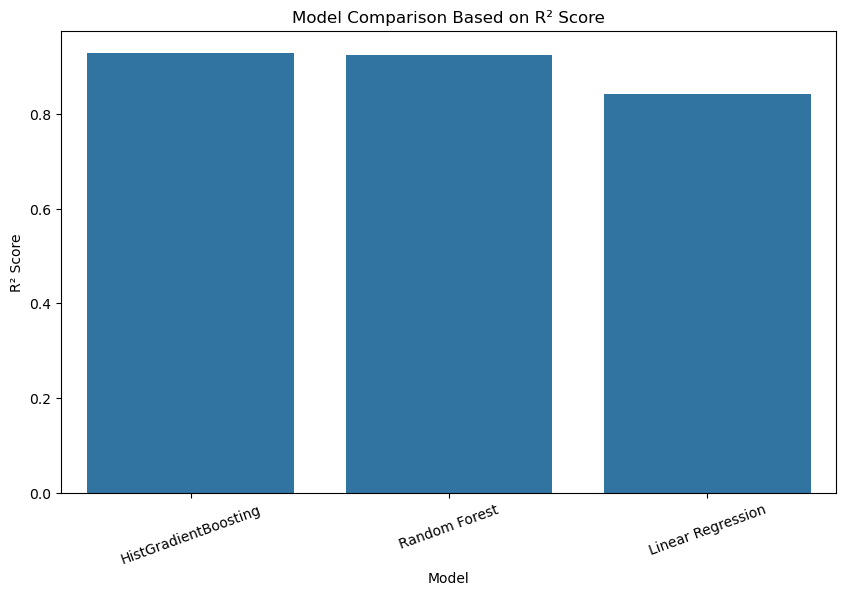

In [63]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x='Model',
    y='R2'
)

plt.title("Model Comparison Based on R² Score")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=20)

plt.show()

- A higher R² indicates that the model explains a greater proportion of the variation in the target variable.

- HistGradientBoosting achieved the highest R² score of 0.9285 and the lowest MAE and RMSE among the three evaluated models. This indicates that it provided the strongest predictive performance for final placement on the test dataset."

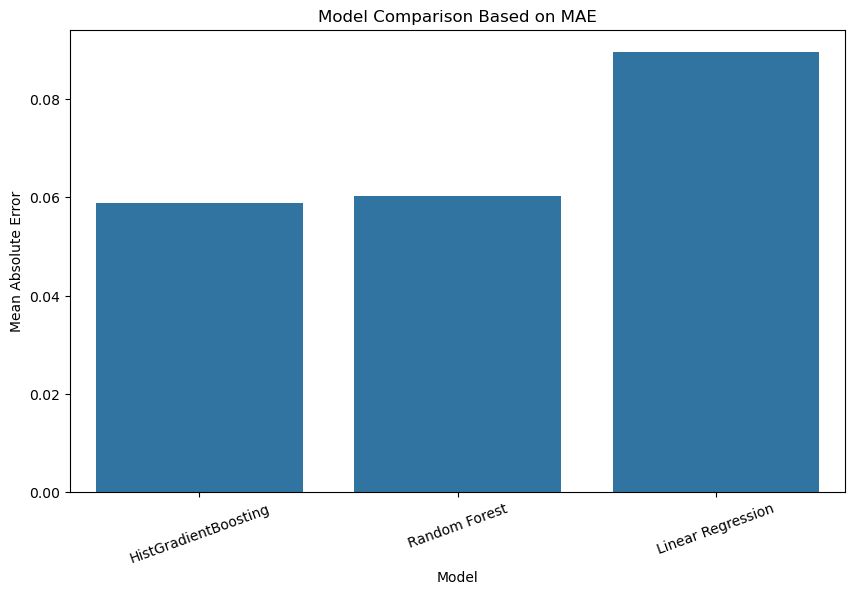

In [58]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x='Model',
    y='MAE'
)

plt.title("Model Comparison Based on MAE")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=20)

plt.show()

- Mean Absolute Error (MAE) measures the average absolute difference between actual and predicted placement.

- The model with the lowest MAE provides predictions that are, on average, closest to the actual placement values. This metric provides an intuitive interpretation of prediction error because it expresses the average magnitude of prediction deviation in the same scale as the target variable.

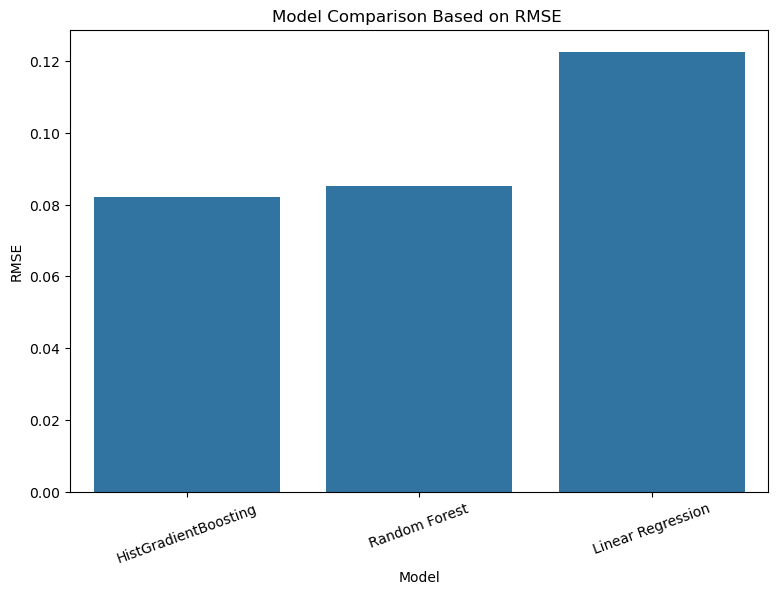

In [67]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=results,
    x='Model',
    y='RMSE'
)

plt.title('Model Comparison Based on RMSE ')
plt.xlabel('Model')
plt.ylabel('RMSE')

plt.xticks(rotation=20)
plt.show()

- Observation:

 The RMSE values of the three regression models were compared to evaluate the magnitude of prediction errors. A lower RMSE indicates better predictive performance, particularly because RMSE gives greater weight to larger prediction errors. Therefore, the model with the lowest RMSE demonstrates the best performance according to this metric.

# Best-Model Selection

In [59]:
best_model_name = results.iloc[0]['Model']

print("Best Model:", best_model_name)

Best Model: HistGradientBoosting


In [60]:
if best_model_name == 'Linear Regression':
    best_pred = linear_pred

elif best_model_name == 'Random Forest':
    best_pred = rf_pred

else:
    best_pred = hist_pred

print("Selected model:", best_model_name)

Selected model: HistGradientBoosting


### Actual Vs Predicted 
This graph compares:

X-axis → actual placement
Y-axis → model-predicted placement

- The Actual vs Predicted plot for HistGradientBoosting shows that the predicted placement values generally follow the diagonal reference line, indicating a strong agreement between actual and predicted values. Some dispersion remains, particularly for observations that are harder to predict, showing that the model does not perfectly explain all variations in player placement.

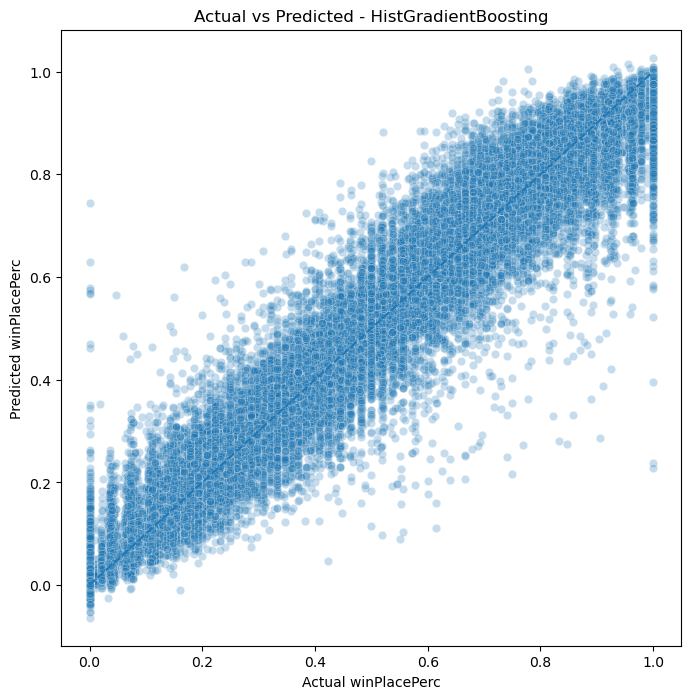

In [61]:
plot_data = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': best_pred
})

plot_data = plot_data.sample(
    min(30000, len(plot_data)),
    random_state=42
)

plt.figure(figsize=(8, 8))

sns.scatterplot(
    data=plot_data,
    x='Actual',
    y='Predicted',
    alpha=0.25
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.title(
    f"Actual vs Predicted - {best_model_name}"
)

plt.xlabel("Actual winPlacePerc")
plt.ylabel("Predicted winPlacePerc")

plt.show()

- Observations :

  The actual-versus-predicted plot provides a visual assessment of model accuracy. A strong model should produce predictions that remain close to the diagonal reference line. Greater dispersion from this line represents larger prediction errors. The plot also helps identify whether the model systematically underpredicts or overpredicts certain placement ranges.

# Final Prediction Error

In [62]:
final_mae = mean_absolute_error(
    y_test,
    best_pred
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        best_pred
    )
)

final_r2 = r2_score(
    y_test,
    best_pred
)

print("FINAL MODEL PERFORMANCE")
print("=======================")
print("Model:", best_model_name)
print("MAE :", round(final_mae, 4))
print("RMSE:", round(final_rmse, 4))
print("R²  :", round(final_r2, 4))

FINAL MODEL PERFORMANCE
Model: HistGradientBoosting
MAE : 0.0589
RMSE: 0.0821
R²  : 0.9285


# Final Observations Found in the Data
### Key Findings

1. The dataset contains approximately 4.45 million player-level observations
   and 29 original variables.

2. Only one missing value was identified, and it occurred in the target
   variable `winPlacePerc`. The corresponding observation was removed.

3. No duplicate rows were identified.

4. Several gameplay variables contain a high proportion of zero values.
   These were retained because zero represents legitimate gameplay behaviour
   rather than missing information.

5. `rankPoints = -1` occurs frequently and was treated as a meaningful
   indicator of unavailable/unranked ranking information rather than as a
   conventional negative numerical error.

6. The target variable `winPlacePerc` ranges from 0 to 1, making the problem
   a regression task.

7. Exploratory analysis showed strong relationships between placement and
   several gameplay variables.

8. `walkDistance` showed the strongest positive correlation with
   `winPlacePerc`, while `killPlace` showed a strong negative correlation.

9. Outlier analysis identified extreme observations in several gameplay
   variables. These were retained because extreme gameplay values can
   represent legitimate player behaviour.

10. Identifier variables such as Id, groupId and matchId were removed before
    model training.

11. Additional features such as total distance, combat score, support item
    usage and damage per kill were created.

12. Multiple regression algorithms were trained and compared using MAE, RMSE
    and R².

13. HistGradientBoosting was selected as the final model because it achieved the highest R² (0.9285) and the lowest MAE (0.0589) and RMSE (0.0821) among the evaluated models.

# Challenges Faced

During the analysis, several challenges were identified while working with the PUBG gameplay dataset:

1. **Large Dataset Size:** The dataset contains approximately 4.45 million observations, making some computationally intensive operations and machine-learning algorithms time-consuming. A reproducible sample of 300,000 training observations was therefore used for the tree-based models.

2. **Missing Target Value:** One missing value was identified in `winPlacePerc`. Since the target value could not be reliably imputed, the corresponding observation was removed.

3. **Categorical Data:** `matchType` contained categorical values such as `duo-fpp` and `squad-fpp`. These values could not be directly processed by numerical machine-learning algorithms, so one-hot encoding was applied.

4. **Large Number of Zero Values:** Several gameplay variables contained a high proportion of zero values. These were retained because zero generally represents valid gameplay behaviour, such as no kills, no revives or no swimming.

5. **Special Ranking Value:** `rankPoints = -1` occurred frequently and was treated as an indicator of unavailable or unranked information rather than as an ordinary negative numerical value.

6. **Outliers:** Several gameplay variables contained extreme observations. These were not automatically removed because extreme values can represent legitimate player behaviour and exceptional gameplay performance.

7. **Feature Scale and Variability:** The numerical variables differed considerably in scale and variability. Appropriate preprocessing, including scaling for Linear Regression, was therefore applied.

8. **Data Leakage Consideration:** Ranking-related variables such as `killPlace` have a strong relationship with final placement. Since this project uses completed gameplay statistics to predict final placement, these variables were retained. For real-time or early-game prediction, such variables would require additional leakage analysis.


# Final Conclusion
This project analyzed PUBG gameplay data to understand the factors associated
with player placement and to develop a machine learning model for predicting
`winPlacePerc`.

The analysis showed that player movement, combat performance, resource
collection and ranking-related variables have important relationships with
final placement. In particular, walk distance demonstrated a strong positive
relationship with placement, while kill place demonstrated a strong negative
relationship.

The dataset required relatively little missing-value treatment because only
one missing target observation was identified. However, the analysis also
highlighted important data characteristics such as large numbers of legitimate
zero values, the presence of `rankPoints = -1`, and substantial statistical
outliers.

After preprocessing and feature engineering, multiple regression models were
trained and evaluated using MAE, RMSE and R². The best-performing model was
selected based on predictive accuracy and generalization performance on the
test set.

Overall, the project demonstrates how exploratory data analysis, data quality
assessment, feature engineering and machine learning can be combined to
understand gameplay behaviour and predict player placement.